RL for logistics Center V2

In [1]:
# Defining an enviroment for the agent (logistics center)
import numpy as np
import random as rd
import copy as cp

# The logistics center is created according to the docks number and SKU numbers
# SKU number = the different number of products avaible in the warehouse
# docker number = the different number of docks in the warehouse
class logistics_center:

    def __init__(self, num_docks = 3, num_SKU = 3, num_deliveries = 4):
        self.num_docks = num_docks
        self.num_SKU = num_SKU
        self.num_deliveries = num_deliveries
        self.my_table = Qtable(lr = 0.02, gamma = 1)

    # the warehouse is a matrix, that contains zeros as "empty space", ones which are the docks, and twos, which are the the SKU positions
    def create_warehouse(self):

        warehouse = np.zeros((self.num_docks, (self.num_docks + 2)))

        for i in range(self.num_docks):
            warehouse[i,0] = 1

        j = 0 

        while j < self.num_SKU:
            a , b = rd.randint(0, (self.num_docks -1)), rd.randint(1, (self.num_docks + 1))
            if warehouse[a,b] == 0:
                warehouse[a, b] = 2
                j += 1

        return warehouse

    # This function is responsible for reseting the enviroment for a new episode to start
    def reset(self):
        self.warehouse = self.create_warehouse()
        self.state = State(self.warehouse, self.num_deliveries)
        self.agent = Agent(self.warehouse, self.state)

    def reward(self):
        if self.agent.invalid_delivery:
            return -20

        delivery = self.agent.current_chosen_delivery

        if self.state.current_episode_time <= self.state.deadline[delivery]:
            return 20

        else:
            return -50


    #here is where we define the episode
    def episode(self):
        self.reset()
        p_state = cp.deepcopy(self.state)
        actions_list =[self.agent.pick_delivery1, self.agent.pick_delivery2, self.agent.pick_delivery3, self.agent.pick_delivery4]
        b = 0
        total_reward_per_episode = 0
        
        while True:
            done = False
            a = self.my_table.choose_action(state=self.state)
            actions_list[a]()
    
            if self.agent.invalid_delivery:
                reward = self.reward()
                total_reward_per_episode += reward

                self.my_table.update_q_table(
                    state=p_state,
                    action=a,
                    reward=reward,
                    next_state=self.state,
                    done=done
                )

                p_state = cp.deepcopy(self.state)

                print("Invalid delivery")
                print("Reward:", reward)

                continue
            
            agent_position = self.state.position
            sku_position = self.state.pick_SKUs[self.agent.current_chosen_delivery]
            dock_position = self.state.delivery_docks[self.agent.current_chosen_delivery]
            distance_a_to_sku = abs(agent_position[0] - sku_position[0]) + abs(agent_position[1] - sku_position[1])
            distance_sku_to_dd = abs(sku_position[0] - dock_position[0]) + abs(sku_position[1] - dock_position[1])
            total_distance = distance_a_to_sku + distance_sku_to_dd
            time = self.state.current_episode_time + total_distance

            if time <= self.state.deadline[self.agent.current_chosen_delivery]:
                b += 1 
                self.state.current_episode_time = time
                self.state.status[self.agent.current_chosen_delivery] = 0
                self.state.position = [int(x) for x in dock_position]
                print(f"Delivery on time: {b}")

            else:
                self.state.current_episode_time = time
                self.state.status[self.agent.current_chosen_delivery] = 0
                self.state.position = [int(x) for x in dock_position]
                print(f"Delivery out of time")

            reward = self.reward()

            if np.array_equal(self.state.status, np.array([0, 0, 0, 0])):
                print("All deliveries were done")
                done = True

            self.my_table.update_q_table(
                state=p_state,
                action=a,
                reward=reward,
                next_state=self.state,
                done=done
            )

            total_reward_per_episode += reward
            
            if done:
                self.my_table.epsilon = max(self.my_table.epsilon*self.my_table.epsilon_decay, self.my_table.epsilon_min)
                break

            p_state = cp.deepcopy(self.state)
            
            print("Position:", self.state.position)
            print("Reward:", reward)
            print("Epsilon:", self.my_table.epsilon)
        return total_reward_per_episode, b

In [2]:
import itertools


class State:

    def __init__(self, warehouse_created, num_deliveries):

        self.num_deliveries = num_deliveries

        # Posições vazias para o agente começar
        empty_positions = np.argwhere(
            warehouse_created == 0
        )

        self.position = empty_positions[
            np.random.randint(len(empty_positions))
        ].copy()

        # Posições dos SKUs
        sku_positions = np.argwhere(
            warehouse_created == 2
        )

        # Posições das docas
        dock_positions = np.argwhere(
            warehouse_created == 1
        )

        # Sorteia os SKUs das entregas
        self.pick_SKUs = np.array([
            sku_positions[
                np.random.randint(len(sku_positions))
            ].copy()
            for _ in range(num_deliveries)
        ])

        # Sorteia as docas das entregas
        self.delivery_docks = np.array([
            dock_positions[
                np.random.randint(len(dock_positions))
            ].copy()
            for _ in range(num_deliveries)
        ])

        # 1 = entrega ainda disponível
        # 0 = entrega concluída
        self.status = np.ones(
            num_deliveries,
            dtype=int
        )

        # Tempo atual do episódio
        self.current_episode_time = 0

        # Cria deadlines factíveis
        self.deadline = self.generate_deadlines()

    def calculate_delivery_time(self, delivery):

        # Agente -> SKU
        agent_to_sku = np.sum(
            np.abs(
                self.position -
                self.pick_SKUs[delivery]
            )
        )

        # SKU -> doca
        sku_to_dock = np.sum(
            np.abs(
                self.pick_SKUs[delivery] -
                self.delivery_docks[delivery]
            )
        )

        return agent_to_sku + sku_to_dock

    def generate_deadlines(self):

        # Testa as 24 ordens possíveis
        for order in itertools.permutations(
            range(self.num_deliveries)
        ):

            current_position = self.position.copy()
            current_time = 0

            deadlines = np.zeros(
                self.num_deliveries,
                dtype=int
            )

            for delivery in order:

                # Posição atual -> SKU
                time_to_sku = np.sum(
                    np.abs(
                        current_position -
                        self.pick_SKUs[delivery]
                    )
                )

                # SKU -> doca
                time_to_dock = np.sum(
                    np.abs(
                        self.pick_SKUs[delivery] -
                        self.delivery_docks[delivery]
                    )
                )

                # Tempo dessa entrega
                delivery_time = (
                    time_to_sku +
                    time_to_dock
                )

                # Tempo acumulado
                current_time += delivery_time

                # Deadline da entrega
                deadlines[delivery] = current_time

                # Depois da entrega, o agente está na doca
                current_position = (
                    self.delivery_docks[delivery].copy()
                )

            # Essa ordem é sempre factível,
            # pois os deadlines foram construídos
            # exatamente com base nela.
            return deadlines

        raise ValueError(
            "Não foi possível gerar os deadlines."
        )

In [3]:
# defining the agent, which is going to have actions and get the state and warehouse created
# the agent can move upwards, downwards and go to the left or to the right, movimentation implemented via matrix 
# we also change the state here, by moving the agent, the dealine is changed as well as the has_SKU state

class Agent():

    def __init__(self, warehouse_created, state):

        self.warehouse_created = warehouse_created
        self.state = state 
        self.invalid_delivery = False

    def pick_delivery1(self):
        self.invalid_delivery = False

        if self.state.status[0] == 1:
            self.current_chosen_delivery = 0
            self.SKU_requisition = self.state.pick_SKUs[0]
            self.delivery_dock = self.state.delivery_docks[0]
            return 0

        self.invalid_delivery = True
        return None


    def pick_delivery2(self):
        self.invalid_delivery = False

        if self.state.status[1] == 1:
            self.current_chosen_delivery = 1
            self.SKU_requisition = self.state.pick_SKUs[1]
            self.delivery_dock = self.state.delivery_docks[1]
            return 1

        self.invalid_delivery = True
        return None

    def pick_delivery3(self):
        self.invalid_delivery = False

        if self.state.status[2] == 1:
            self.current_chosen_delivery = 2
            self.SKU_requisition = self.state.pick_SKUs[2]
            self.delivery_dock = self.state.delivery_docks[2]
            return 2

        self.invalid_delivery = True
        return None
    
    def pick_delivery4(self):
        self.invalid_delivery = False

        if self.state.status[3] == 1:
            self.current_chosen_delivery = 3
            self.SKU_requisition = self.state.pick_SKUs[3]
            self.delivery_dock = self.state.delivery_docks[3]
            return 3

        self.invalid_delivery = True
        return None

In [4]:
# the first model we will try it's gonna be Q-Learning

class Qtable():

    def __init__(self, lr, gamma, epsilon=1.0, epsilon_decay=0.995, epsilon_min=0.01):
        self.lr = lr
        self.gamma = gamma

        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.epsilon_min = epsilon_min

        self.q_table = {}

    def get_q_values(self, state):

        state_key = self.state_to_key(state)

        if state_key not in self.q_table:
            self.q_table[state_key] = np.zeros(4)

        return self.q_table[state_key]

    def state_to_key(self, state):

        position = tuple(state.position)

        deliveries = tuple(
            (
                tuple(state.pick_SKUs[i]),
                tuple(state.delivery_docks[i]),
                state.deadline[i]
            )
            for i in range(len(state.status))
            if state.status[i] == 1
        )

        current_episode_time = state.current_episode_time

        return (
            position,
            deliveries,
            current_episode_time
        )

    def choose_action(self, state):

        q_values = self.get_q_values(state)

        possible_actions = []

        for i in range(len(state.status)):
            if state.status[i] == 1:
                possible_actions.append(i)

        # Exploração
        if np.random.rand() < self.epsilon:
            action = np.random.choice(possible_actions)

        # Aproveitamento
        else:
            possible_q_values = q_values[possible_actions]
            action = possible_actions[np.argmax(possible_q_values)]

        return action

    def update_q_table(self, state, action, reward, next_state, done):

        current_q_values = self.get_q_values(state)
        next_q_values = self.get_q_values(next_state)

        current_q = current_q_values[action]

        if done:

            target = reward

        else:

            possible_next_actions = []

            for i in range(len(next_state.status)):
                if next_state.status[i] == 1:
                    possible_next_actions.append(i)

            if possible_next_actions:
                max_next_q = np.max(next_q_values[possible_next_actions])
            else:
                max_next_q = 0

            target = reward + self.gamma * max_next_q

        self.q_table[self.state_to_key(state)][action] = (
            current_q + self.lr * (target - current_q)
        )

In [5]:
env = logistics_center()
rewards_list = []
deliveries_on_time_list = []
env.my_table.epsilon_decay = 0.999

for episode in range(7000):
    print(f"\n--- Episode {episode + 1} ---")
    a, b = env.episode()
    rewards_list.append(a)
    deliveries_on_time_list.append(b)



--- Episode 1 ---
Delivery on time: 1
Position: [1, 0]
Reward: 20
Epsilon: 1.0
Delivery out of time
Position: [2, 0]
Reward: -50
Epsilon: 1.0
Delivery on time: 2
Position: [1, 0]
Reward: 20
Epsilon: 1.0
Delivery out of time
All deliveries were done

--- Episode 2 ---
Delivery on time: 1
Position: [0, 0]
Reward: 20
Epsilon: 0.999
Delivery on time: 2
Position: [1, 0]
Reward: 20
Epsilon: 0.999
Delivery out of time
Position: [2, 0]
Reward: -50
Epsilon: 0.999
Delivery out of time
All deliveries were done

--- Episode 3 ---
Delivery on time: 1
Position: [1, 0]
Reward: 20
Epsilon: 0.998001
Delivery on time: 2
Position: [0, 0]
Reward: 20
Epsilon: 0.998001
Delivery on time: 3
Position: [0, 0]
Reward: 20
Epsilon: 0.998001
Delivery out of time
All deliveries were done

--- Episode 4 ---
Delivery on time: 1
Position: [2, 0]
Reward: 20
Epsilon: 0.997002999
Delivery on time: 2
Position: [0, 0]
Reward: 20
Epsilon: 0.997002999
Delivery on time: 3
Position: [2, 0]
Reward: 20
Epsilon: 0.997002999
Deliv

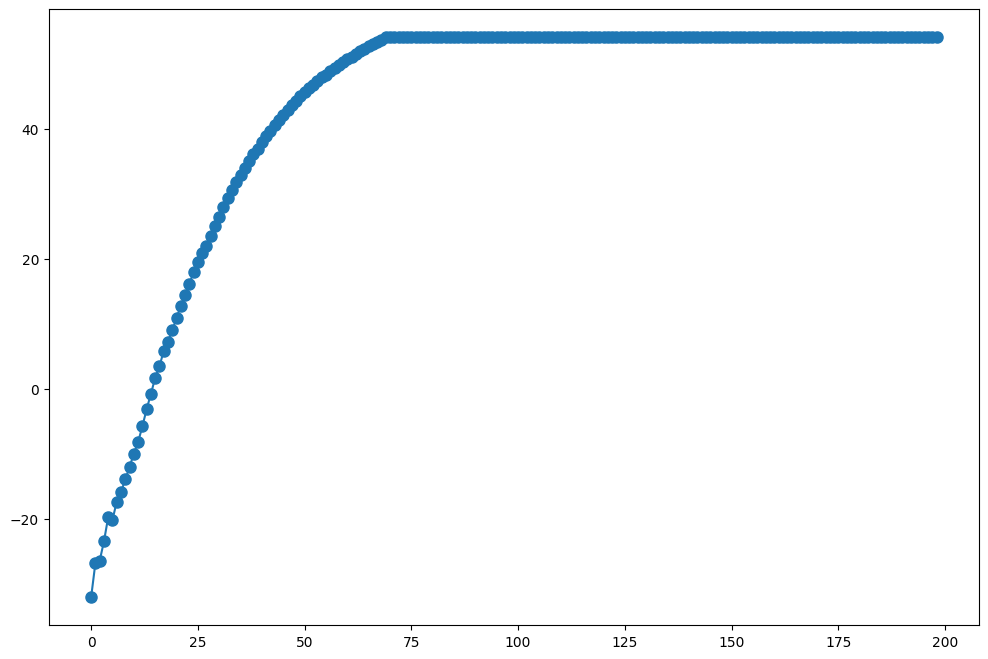

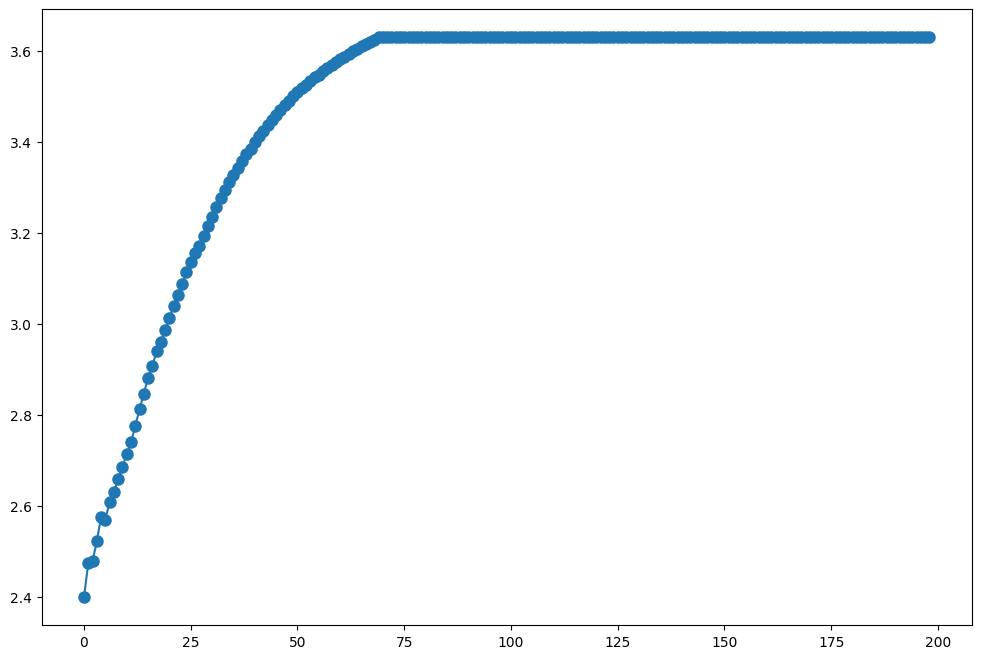

In [6]:
import matplotlib.pyplot as plt

mean_rewards = []
mean_deliveries = []
for i in range(100, 20000, 100):
    mean_reward = sum(rewards_list[:i])/len(rewards_list[:i])
    mean_deliverie = sum(deliveries_on_time_list[:i])/len(deliveries_on_time_list[:i])
    mean_rewards.append(mean_reward)
    mean_deliveries.append(mean_deliverie)


plt.figure(figsize=(12,8))
plt.plot(range(len(mean_rewards)), mean_rewards, marker = 'o', markersize = 8)
plt.figure(figsize=(12,8))
plt.plot(range(len(mean_deliveries)), mean_deliveries, marker = 'o', markersize = 8)

Now, the ideia is to upgrade the model, with a more complex problem so we are going to make some changes at the original logistics center


In [7]:
from collections import deque
class logistics_center2:

    def __init__(self, num_docks=10, num_SKU=4, num_deliveries=10,
                 top_k=3, lr=0.1, gamma=0.95,
                 epsilon=1.0, epsilon_decay=0.998, epsilon_min=0.01):
        self.num_docks = num_docks
        self.num_SKU = num_SKU
        self.num_deliveries = num_deliveries
        self.top_k = top_k          
        self.warehouse = self.create_warehouse()
        self._dist_cache = {}

        self.my_table = Qtable2(lr=lr, gamma=gamma, top_k=top_k,
                                epsilon=epsilon, epsilon_decay=epsilon_decay,
                                epsilon_min=epsilon_min)

    # 0 = espaço vazio, 1 = docas, 2 = posições de SKU (prateleiras)
    def create_warehouse(self):
        warehouse = np.zeros((self.num_docks, self.num_docks))
        for i in range(self.num_docks):
            if i < 5:
                warehouse[i, 0] = 1
            else:
                warehouse[0, i - 4] = 1
        for j in range(2, self.num_SKU * 2 + 1, 2):
            warehouse[j, 2:8] = 2
        return warehouse

    # Menor caminho (BFS) sem atravessar prateleiras. Resultado fica em cache.
    def shortest_path_distance(self, start, target):
        start = (int(start[0]), int(start[1]))
        target = (int(target[0]), int(target[1]))

        key = (start, target)
        if key in self._dist_cache:
            return self._dist_cache[key]

        distance = self._bfs(start, target)
        self._dist_cache[key] = distance
        return distance

    def _bfs(self, start, target):
        if start == target:
            return 0

        movements = [(-1, 0), (1, 0), (0, -1), (0, 1)]
        queue = deque([(start, 0)])
        visited = {start}

        while queue:
            (row, col), distance = queue.popleft()

            for d_row, d_col in movements:
                nxt = (row + d_row, col + d_col)

                if not (0 <= nxt[0] < self.warehouse.shape[0]
                        and 0 <= nxt[1] < self.warehouse.shape[1]):
                    continue
                if nxt in visited:
                    continue
                if nxt == target:               # o destino pode ser um SKU
                    return distance + 1
                if self.warehouse[nxt] == 2:    # não atravessa outros SKUs
                    continue

                visited.add(nxt)
                queue.append((nxt, distance + 1))

        return None

    # Prepara um novo episódio
    def reset(self):
        self.state = State2(self.warehouse, self.num_deliveries, self, self.top_k)
        self.agent = Agent2(self.warehouse, self.state)

    def reward(self, on_time):
        return 20 if on_time else -50

    # Um episódio completo. train=False => política gulosa, sem aprender.
    def episode(self, train=True):
        self.reset()
        state, agent, table = self.state, self.agent, self.my_table

        on_time_count = 0
        total_reward = 0

        cands, obs = state.observation()

        while True:
            action = table.choose_action(obs, len(cands), greedy=not train)
            delivery = agent.pick_delivery(action, cands)

            on_time = agent.execute_delivery(delivery)
            reward = self.reward(on_time)

            on_time_count += on_time
            total_reward += reward
            done = not state.status.any()

            if done:
                next_cands, next_obs = [], None
            else:
                next_cands, next_obs = state.observation()

            if train:
                table.update_q_table(obs, action, reward, next_obs, len(next_cands), done)

            if done:
                break
            cands, obs = next_cands, next_obs

        if train:
            table.decay_epsilon()

        return total_reward, on_time_count

    # Média de entregas no prazo com política gulosa (não altera a Q-table)
    def evaluate(self, n_episodes=500):
        return float(np.mean([self.episode(train=False)[1] for _ in range(n_episodes)]))

In [8]:
class State2:

    # Limites da folga (deadline - tempo de chegada) usados para discretizar o estado:
    # <0 | 0-3 | 4-9 | 10-19 | >=20
    SLACK_BINS = [0, 4, 10, 20]

    def __init__(self, warehouse_created, num_deliveries, environment, top_k=3, deadline_slack=1.5):
        self.num_deliveries = num_deliveries
        self.warehouse_created = warehouse_created
        self.environment = environment
        self.top_k = top_k
        self.deadline_slack = deadline_slack

        # Posição inicial do agente (célula vazia)
        empty_positions = np.argwhere(warehouse_created == 0)
        self.position = empty_positions[np.random.randint(len(empty_positions))].copy()

        sku_positions = np.argwhere(warehouse_created == 2)
        dock_positions = np.argwhere(warehouse_created == 1)

        # SKU e doca de cada entrega
        self.pick_SKUs = np.array([
            sku_positions[np.random.randint(len(sku_positions))].copy()
            for _ in range(num_deliveries)
        ])
        self.delivery_docks = np.array([
            dock_positions[np.random.randint(len(dock_positions))].copy()
            for _ in range(num_deliveries)
        ])

        # 1 = entrega pendente, 0 = entrega concluída
        self.status = np.ones(num_deliveries, dtype=int)
        self.current_episode_time = 0

        # Deadlines sempre factíveis (construídos a partir de uma ordem real de entrega)
        self.deadline = self.generate_deadlines()

    def calculate_delivery_time(self, delivery):
        # posição atual -> SKU -> doca
        agent_to_sku = self.environment.shortest_path_distance(self.position, self.pick_SKUs[delivery])
        sku_to_dock = self.environment.shortest_path_distance(self.pick_SKUs[delivery], self.delivery_docks[delivery])

        if agent_to_sku is None or sku_to_dock is None:
            return None
        return agent_to_sku + sku_to_dock

    def generate_deadlines(self):
        order = np.random.permutation(self.num_deliveries)

        current_position = self.position.copy()
        current_time = 0
        deadlines = np.zeros(self.num_deliveries, dtype=int)

        for delivery in order:
            time_to_sku = self.environment.shortest_path_distance(current_position, self.pick_SKUs[delivery])
            time_to_dock = self.environment.shortest_path_distance(self.pick_SKUs[delivery], self.delivery_docks[delivery])

            if time_to_sku is None or time_to_dock is None:
                return self.generate_deadlines()

            current_time += time_to_sku + time_to_dock
            deadlines[delivery] = int(current_time * self.deadline_slack)
            current_position = self.delivery_docks[delivery].copy()

        return deadlines

    # As top_k entregas pendentes com menor deadline (índice 0 = a mais urgente)
    def candidates(self):
        pending = [i for i in range(self.num_deliveries) if self.status[i] == 1]
        pending.sort(key=lambda i: self.deadline[i])
        return pending[:self.top_k]

    # Retorna (candidatas, observação). A observação é a folga discretizada de cada candidata.
    def observation(self):
        cands = self.candidates()
        features = []
        for i in cands:
            arrival = self.current_episode_time + self.calculate_delivery_time(i)
            slack = self.deadline[i] - arrival
            features.append(int(np.searchsorted(self.SLACK_BINS, slack, side="right")))

        features += [-1] * (self.top_k - len(features))   # preenche quando restam poucas entregas
        return cands, tuple(features)

In [9]:
class Agent2():

    def __init__(self, warehouse_created, state):
        self.warehouse_created = warehouse_created
        self.state = state

    # A ação é um RANK: 0 = entrega de prazo mais próximo, 1 = a segunda, ...
    # Converte esse rank no índice real da entrega.
    def pick_delivery(self, action, candidates):
        self.current_chosen_delivery = candidates[action]
        self.SKU_requisition = self.state.pick_SKUs[self.current_chosen_delivery]
        self.delivery_dock = self.state.delivery_docks[self.current_chosen_delivery]
        return self.current_chosen_delivery

    # Executa a entrega: avança o tempo, move o agente até a doca e marca como concluída.
    # Retorna True se foi entregue dentro do prazo.
    def execute_delivery(self, delivery):
        state = self.state

        state.current_episode_time += state.calculate_delivery_time(delivery)
        state.position = np.array(state.delivery_docks[delivery])
        state.status[delivery] = 0

        return bool(state.current_episode_time <= state.deadline[delivery])

In [10]:
class Qtable2():

    def __init__(self, lr, gamma, top_k=3, epsilon=1.0, epsilon_decay=0.998, epsilon_min=0.01):
        self.lr = lr
        self.gamma = gamma
        self.top_k = top_k

        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.epsilon_min = epsilon_min

        self.q_table = {}

    def get_q_values(self, obs):
        if obs not in self.q_table:
            self.q_table[obs] = np.zeros(self.top_k)
        return self.q_table[obs]

    # n_valid = quantas candidatas existem agora (as ações válidas são 0 .. n_valid-1)
    def choose_action(self, obs, n_valid, greedy=False):
        if not greedy and np.random.rand() < self.epsilon:
            return np.random.randint(n_valid)
        return int(np.argmax(self.get_q_values(obs)[:n_valid]))

    def update_q_table(self, obs, action, reward, next_obs, n_next_valid, done):
        q_values = self.get_q_values(obs)

        if done:
            target = reward
        else:
            max_next_q = np.max(self.get_q_values(next_obs)[:n_next_valid])
            target = reward + self.gamma * max_next_q

        q_values[action] += self.lr * (target - q_values[action])

    def decay_epsilon(self):
        self.epsilon = max(self.epsilon * self.epsilon_decay, self.epsilon_min)

In [11]:
np.random.seed(0); rd.seed(0)

env2 = logistics_center2(top_k=3, lr=0.1, gamma=0.95, epsilon_decay=0.998)

rewards_list = []
deliveries_on_time_list = []

for episode in range(3000):
    r, b = env2.episode(train=True)
    rewards_list.append(r)
    deliveries_on_time_list.append(b)
    if (episode + 1) % 500 == 0:
        print(f"Episódio {episode+1:5d} | epsilon={env2.my_table.epsilon:.3f} | "
              f"no prazo (média últimos 100): {np.mean(deliveries_on_time_list[-100:]):.2f}/10")



Episódio   500 | epsilon=0.368 | no prazo (média últimos 100): 9.18/10
Episódio  1000 | epsilon=0.135 | no prazo (média últimos 100): 9.53/10
Episódio  1500 | epsilon=0.050 | no prazo (média últimos 100): 9.81/10
Episódio  2000 | epsilon=0.018 | no prazo (média últimos 100): 9.92/10
Episódio  2500 | epsilon=0.010 | no prazo (média últimos 100): 9.97/10
Episódio  3000 | epsilon=0.010 | no prazo (média últimos 100): 9.94/10


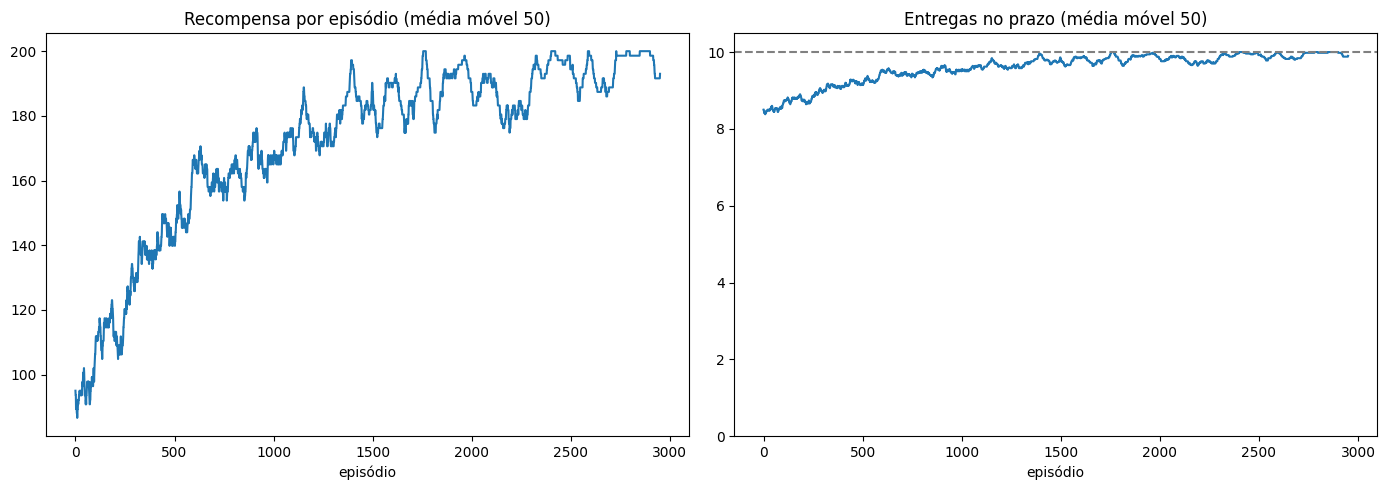

In [12]:
def moving_avg(x, w=50):
    return np.convolve(x, np.ones(w)/w, mode="valid")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(moving_avg(rewards_list))
ax[0].set_title("Recompensa por episódio (média móvel 50)")
ax[0].set_xlabel("episódio")

ax[1].plot(moving_avg(deliveries_on_time_list))
ax[1].axhline(10, ls="--", c="gray")
ax[1].set_title("Entregas no prazo (média móvel 50)")
ax[1].set_ylim(0, 10.5)
ax[1].set_xlabel("episódio")

plt.tight_layout()
plt.show()


Now the ideia is to Upgrade to model to simulate multiple people working at the warehouse at the same time

In [40]:
class logistics_center2:

    def __init__(self, num_docks=10, num_SKU=4, num_deliveries=20,
                 top_k=3, lr=0.1, gamma=0.95,
                 epsilon=1.0, epsilon_decay=0.998, epsilon_min=0.01, num_operators = 4):
        self.num_operators = num_operators
        self.num_docks = num_docks
        self.num_SKU = num_SKU
        self.num_deliveries = num_deliveries
        self.top_k = top_k          
        self.block_penalty = 15
        self.warehouse = self.create_warehouse()
        self._dist_cache = {}

        self.my_table = Qtable2(lr=lr, gamma=gamma, top_k=top_k,
                                epsilon=epsilon, epsilon_decay=epsilon_decay,
                                epsilon_min=epsilon_min)

    # 0 = espaço vazio, 1 = docas, 2 = posições de SKU (prateleiras)
    def create_warehouse(self):
        warehouse = np.zeros((self.num_docks, self.num_docks))
        for i in range(self.num_docks):
            if i < 5:
                warehouse[i, 0] = 1
            else:
                warehouse[0, i - 4] = 1
        for j in range(2, self.num_SKU * 2 + 1, 2):
            warehouse[j, 2:8] = 2
        return warehouse

    # Menor caminho (BFS) sem atravessar prateleiras. Resultado fica em cache.
    def shortest_path_distance(self, start, target):
        start = (int(start[0]), int(start[1]))
        target = (int(target[0]), int(target[1]))

        key = (start, target)
        if key in self._dist_cache:
            return self._dist_cache[key]

        distance = self._bfs(start, target)
        self._dist_cache[key] = distance
        return distance

    def _bfs(self, start, target):
        if start == target:
            return 0

        movements = [(-1, 0), (1, 0), (0, -1), (0, 1)]
        queue = deque([(start, 0)])
        visited = {start}

        while queue:
            (row, col), distance = queue.popleft()

            for d_row, d_col in movements:
                nxt = (row + d_row, col + d_col)

                if not (0 <= nxt[0] < self.warehouse.shape[0]
                        and 0 <= nxt[1] < self.warehouse.shape[1]):
                    continue
                if nxt in visited:
                    continue
                if nxt == target:               # o destino pode ser um SKU
                    return distance + 1
                if self.warehouse[nxt] == 2:    # não atravessa outros SKUs
                    continue

                visited.add(nxt)
                queue.append((nxt, distance + 1))

        return None

    # Prepara um novo episódio
    def reset(self):
        self.state = State2(self.warehouse, self.num_deliveries, self, self.top_k, num_operators = self.num_operators)
        self.agent = Agent2(self.warehouse, self.state)

    def reward(self, on_time, blocked):
        r = 20 if on_time else -50
        if blocked:
            r -= self.block_penalty      # punição extra por mandar para corredor ocupado
        return r

    def episode(self, train=True):
        self.reset()
        state, agent, table = self.state, self.agent, self.my_table

        on_time_count = 0
        blocked_count = 0
        total_reward = 0

        operator = state.next_operator()
        cands, obs = state.observation(operator)

        while True:
            action = table.choose_action(obs, len(cands), greedy=not train)
            delivery = agent.pick_delivery(action, cands)

            on_time, blocked = agent.execute_delivery(delivery, operator)   # MUDOU: dois valores
            reward = self.reward(on_time, blocked)                          # MUDOU

            on_time_count += on_time
            blocked_count += blocked                                        # NOVO: métrica
            total_reward += reward
            done = not state.status.any()

            if done:
                next_cands, next_obs = [], None
            else:
                operator = state.next_operator()
                next_cands, next_obs = state.observation(operator)

            if train:
                table.update_q_table(obs, action, reward, next_obs, len(next_cands), done)

            if done:
                break
            cands, obs = next_cands, next_obs

        if train:
            table.decay_epsilon()

        return total_reward, on_time_count, blocked_count                  # MUDOU: 3 valores

    # Média de entregas no prazo com política gulosa (não altera a Q-table)
    def evaluate(self, n_episodes=500):
        return float(np.mean([self.episode(train=False)[1] for _ in range(n_episodes)]))

In [41]:
class State2:

    # Limites da folga (deadline - tempo de chegada): <0 | 0-3 | 4-9 | 10-19 | >=20
    SLACK_BINS = [0, 4, 10, 20]

    def __init__(self, warehouse_created, num_deliveries, environment,
                 top_k=3, deadline_slack=1, num_operators=1):
        self.num_deliveries = num_deliveries
        self.warehouse_created = warehouse_created
        self.environment = environment
        self.top_k = top_k
        self.deadline_slack = deadline_slack
        self.num_operators = num_operators

        # NOVO: posição inicial de cada operador (células vazias DISTINTAS).
        # Um array (num_operators, 2) em vez de position_agent1/position_agent2:
        # o mesmo código serve para 2, 4 ou 5 operadores.
        empty_positions = np.argwhere(warehouse_created == 0)
        chosen = np.random.choice(len(empty_positions), size=num_operators, replace=False)
        self.positions = empty_positions[chosen].copy()

        # NOVO: instante em que cada operador fica livre.
        # Substitui o antigo current_episode_time (que era um tempo único).
        self.free_at = np.zeros(num_operators, dtype=int)
        self.busy_until = np.zeros(self.environment.num_SKU + 1, dtype=int)

        sku_positions = np.argwhere(warehouse_created == 2)
        dock_positions = np.argwhere(warehouse_created == 1)

        self.pick_SKUs = np.array([
            sku_positions[np.random.randint(len(sku_positions))].copy()
            for _ in range(num_deliveries)
        ])
        self.delivery_corridor = (self.pick_SKUs[:, 0] - 1)//2 + np.random.randint(0, 2, size = num_deliveries) # 0 = cima, 1 = baixo

        self.delivery_docks = np.array([
            dock_positions[np.random.randint(len(dock_positions))].copy()
            for _ in range(num_deliveries)
        ])

        # 1 = entrega pendente, 0 = entrega concluída
        self.status = np.ones(num_deliveries, dtype=int)

        self.deadline = self.generate_deadlines()

    # NOVO: quem decide agora é o operador que fica livre primeiro
    def next_operator(self):
        return int(np.argmin(self.free_at))

    # MUDOU: recebe o operador e calcula o tempo a partir da posição DELE
    def calculate_delivery_time(self, delivery, operator):
        to_sku = self.environment.shortest_path_distance(self.positions[operator], self.pick_SKUs[delivery])
        sku_to_dock = self.environment.shortest_path_distance(self.pick_SKUs[delivery], self.delivery_docks[delivery])

        if to_sku is None or sku_to_dock is None:
            return None
        return to_sku + sku_to_dock

    # Ainda gera deadlines a partir de UMA sequência com o operador 0
    # (ficam folgados para 2 operadores; apertar isso é a próxima etapa).
    # MUDOU: os deadlines agora vêm de um plano real com TODOS os operadores.
    def generate_deadlines(self):
        order = np.random.permutation(self.num_deliveries)

        # cópias LOCAIS para simular o plano sem tocar no estado real
        positions = self.positions.copy()
        free_at = np.zeros(self.num_operators, dtype=int)
        busy_until = np.zeros(self.environment.num_SKU + 1, dtype=int)
        deadlines = np.zeros(self.num_deliveries, dtype=int)

        for delivery in order:
            operator = int(np.argmin(free_at))                 # mesma regra do episódio
            corridor = self.delivery_corridor[delivery]

            time_to_sku = self.environment.shortest_path_distance(positions[operator], self.pick_SKUs[delivery])
            time_to_dock = self.environment.shortest_path_distance(self.pick_SKUs[delivery], self.delivery_docks[delivery])

            if time_to_sku is None or time_to_dock is None:
                return self.generate_deadlines()

            beginning = max(free_at[operator], busy_until[corridor])   # espera o corredor liberar
            finish = beginning + time_to_sku + time_to_dock

            free_at[operator] = finish
            positions[operator] = self.delivery_docks[delivery]
            busy_until[corridor] = finish
            deadlines[delivery] = int(finish * self.deadline_slack)    # slack aqui

        return deadlines

    def candidates(self, operator):
        pending = [i for i in range(self.num_deliveries) if self.status[i] == 1]
        pending.sort(key=lambda i: self.deadline[i])

        now = self.free_at[operator]     # instante da decisão
        free = [i for i in pending if self.busy_until[self.delivery_corridor[i]] <= now]
        busy = [i for i in pending if self.busy_until[self.delivery_corridor[i]] > now]

        # entregas com corredor livre vêm primeiro; as ocupadas só completam se faltar
        chosen = (free + busy)[:self.top_k]
        chosen.sort(key=lambda i: self.deadline[i])   # rank 0 = mais urgente entre as escolhidas
        return chosen

    def observation(self, operator):
        cands = self.candidates(operator)
        features = []
        for i in cands:
            variable = self.delivery_corridor[i]
            probable_beginning = max(self.free_at[operator], self.busy_until[variable])
            arrival = probable_beginning + self.calculate_delivery_time(i, operator)
            slack = self.deadline[i] - arrival
            features.append(int(np.searchsorted(self.SLACK_BINS, slack, side="right")))

            if self.busy_until[variable] > self.free_at[operator]:
                occupied = 1
            else:
                occupied = 0
            features.append(occupied)
        

        features += [-1] * (2 * self.top_k - len(features))
        return cands, tuple(features)

In [42]:
class Agent2():

    def __init__(self, warehouse_created, state):
        self.warehouse_created = warehouse_created
        self.state = state

    # A ação é um RANK: 0 = entrega de prazo mais próximo, 1 = a segunda, ...
    # Converte esse rank no índice real da entrega.
    def pick_delivery(self, action, candidates):
        self.current_chosen_delivery = candidates[action]
        self.SKU_requisition = self.state.pick_SKUs[self.current_chosen_delivery]
        self.delivery_dock = self.state.delivery_docks[self.current_chosen_delivery]
        return self.current_chosen_delivery

    # Executa a entrega: avança o tempo, move o agente até a doca e marca como concluída.
    # Retorna True se foi entregue dentro do prazo.
        # MUDOU: recebe o operador; só ELE tem posição e free_at atualizados
    def execute_delivery(self, delivery, operator):
        state = self.state

        corridor = state.delivery_corridor[delivery]

        # 1. Verifica o bloqueio ANTES de alterar qualquer valor
        blocked = state.busy_until[corridor] > state.free_at[operator]

        # 2. O operador só começa quando o corredor estiver livre
        start = max(state.free_at[operator], state.busy_until[corridor])
        finish = start + state.calculate_delivery_time(delivery, operator)

        # 3. Atualiza o estado (o corredor fica ocupado até o fim da entrega)
        state.free_at[operator] = finish
        state.positions[operator] = state.delivery_docks[delivery]
        state.status[delivery] = 0
        state.busy_until[corridor] = finish

        return bool(finish <= state.deadline[delivery]), blocked

In [48]:
np.random.seed(0); rd.seed(0)

env2 = logistics_center2(top_k=3, lr=0.1, gamma=0.95, epsilon_decay=0.998, num_operators=4)

rewards_list = []
deliveries_on_time_list = []
blocks = []

for episode in range(8000):
    r, b, k = env2.episode(train=True)
    rewards_list.append(r)
    deliveries_on_time_list.append(b)
    blocks.append(k)
    if (episode + 1) % 500 == 0:
        print(f"Episódio {episode+1:5d} | epsilon={env2.my_table.epsilon:.3f} | " 
              f"Bloqueios(média últimos 100): {np.mean(blocks[-100:]):.2f}/20 | "
              f"no prazo (média últimos 100): {np.mean(deliveries_on_time_list[-100:]):.2f}/20"
               )



Episódio   500 | epsilon=0.368 | Bloqueios(média últimos 100): 5.52/20 | no prazo (média últimos 100): 16.23/20
Episódio  1000 | epsilon=0.135 | Bloqueios(média últimos 100): 5.00/20 | no prazo (média últimos 100): 16.19/20
Episódio  1500 | epsilon=0.050 | Bloqueios(média últimos 100): 4.56/20 | no prazo (média últimos 100): 15.93/20
Episódio  2000 | epsilon=0.018 | Bloqueios(média últimos 100): 4.43/20 | no prazo (média últimos 100): 16.96/20
Episódio  2500 | epsilon=0.010 | Bloqueios(média últimos 100): 4.98/20 | no prazo (média últimos 100): 16.76/20
Episódio  3000 | epsilon=0.010 | Bloqueios(média últimos 100): 4.95/20 | no prazo (média últimos 100): 17.40/20
Episódio  3500 | epsilon=0.010 | Bloqueios(média últimos 100): 4.86/20 | no prazo (média últimos 100): 16.99/20
Episódio  4000 | epsilon=0.010 | Bloqueios(média últimos 100): 5.16/20 | no prazo (média últimos 100): 17.83/20
Episódio  4500 | epsilon=0.010 | Bloqueios(média últimos 100): 5.02/20 | no prazo (média últimos 100): 1

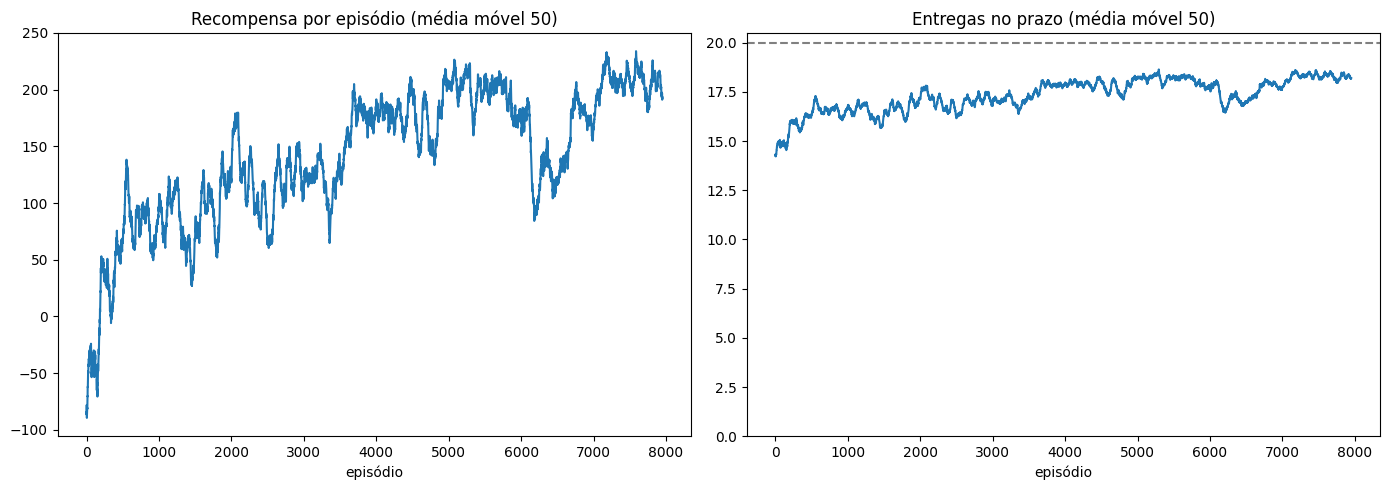

In [49]:
def moving_avg(x, w=50):
    return np.convolve(x, np.ones(w)/w, mode="valid")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(moving_avg(rewards_list))
ax[0].set_title("Recompensa por episódio (média móvel 50)")
ax[0].set_xlabel("episódio")

ax[1].plot(moving_avg(deliveries_on_time_list))
ax[1].axhline(20, ls="--", c="gray")
ax[1].set_title("Entregas no prazo (média móvel 50)")
ax[1].set_ylim(0, 20.5)
ax[1].set_xlabel("episódio")

plt.tight_layout()
plt.show()


In [ ]:
##Menor prazo
def test_policy(policy, num_operators=4, n_episodes=1000, seed=0):
    np.random.seed(seed); rd.seed(seed)
    env = logistics_center2(num_operators=num_operators)

    on_time_list, blocked_list = [], []
    for _ in range(n_episodes):
        env.reset()
        state, agent = env.state, env.agent
        on_time_count, blocked_count = 0, 0

        while state.status.any():
            operator = state.next_operator()
            pending = [i for i in range(env.num_deliveries) if state.status[i] == 1]

            delivery = policy(state, operator, pending)     # a política escolhe a entrega
            on_time, blocked = agent.execute_delivery(delivery, operator)

            on_time_count += on_time
            blocked_count += blocked

        on_time_list.append(on_time_count)
        blocked_list.append(blocked_count)

    return np.mean(on_time_list), np.mean(blocked_list)


# Regra "menor prazo": escolhe a entrega pendente com o menor deadline
def earliest_deadline(state, operator, pending):
    return min(pending, key=lambda i: state.deadline[i])


for nop in (1, 2, 3, 4):
    a, b = test_policy(earliest_deadline, nop)
    print(f"Menor prazo | {nop} op | no prazo {a:.2f}/10 | bloqueios/ep {b:.2f}")

Menor prazo | 1 op | no prazo 20.00/10 | bloqueios/ep 0.00
Menor prazo | 2 op | no prazo 14.22/10 | bloqueios/ep 3.64
Menor prazo | 3 op | no prazo 14.92/10 | bloqueios/ep 6.57
Menor prazo | 4 op | no prazo 14.49/10 | bloqueios/ep 9.02


In [50]:
env2.evaluate(1000)

18.327